# Predição da propensão de compra em sessões de navegação

## Objetivo

Este notebook compara três classificadores para estimar se uma sessão de navegação termina em compra (`Revenue`): **Regressão Logística**, **Random Forest** e **XGBoost**. A seleção prioriza a AUC-ROC média na validação cruzada; o F1-Score é o critério secundário. Precisão, recall, acurácia, desempenho no teste, interpretabilidade e complexidade também serão considerados.

A base utilizada é o *Online Shoppers Purchasing Intention Dataset*, disponibilizado no UCI Machine Learning Repository. As análises e métricas serão calculadas a partir do CSV carregado; nenhum resultado é presumido neste arquivo.

**Nota metodológica:** serão mantidas as linhas duplicadas identificadas, pois não há identificador de sessão que permita confirmar que registros idênticos representam o mesmo evento. Valores extremos pelo IQR serão quantificados, mas não removidos nem limitados automaticamente. A distribuição original da variável-alvo será preservada.

## 1. Bibliotecas e configurações

Execute as células em ordem. O arquivo `online_shoppers_intention.csv` deve estar na mesma pasta do notebook, ou o caminho pode ser alterado na variável `CAMINHO_CSV` abaixo. A pasta `output` será criada quando esta célula for executada.

Se alguma biblioteca estiver ausente, instale as dependências necessárias manualmente, por exemplo em uma célula separada: `python -m pip install pandas numpy matplotlib scikit-learn xgboost`.

In [2]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

# Configurações centralizadas
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5
LIMIAR_CLASSIFICACAO = 0.5
CAMINHO_CSV = Path("online_shoppers_intention.csv")
PASTA_SAIDA = Path("output")
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

COLUNAS_NUMERICAS = [
    "Administrative", "Administrative_Duration", "Informational",
    "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay",
]
COLUNAS_CATEGORICAS = [
    "Month", "OperatingSystems", "Browser", "Region", "TrafficType",
    "VisitorType", "Weekend",
]
COLUNA_ALVO = "Revenue"
COLUNAS_PREDITORAS = COLUNAS_NUMERICAS + COLUNAS_CATEGORICAS
COLUNAS_ESPERADAS = COLUNAS_PREDITORAS + [COLUNA_ALVO]

REFERENCIA_UCI = {"linhas": 12330, "colunas": 18, "sem_compra": 10422, "com_compra": 1908, "duplicadas": 125}

print(f"Pasta de saída configurada em: {PASTA_SAIDA.resolve()}")
print(f"Arquivo CSV configurado em: {CAMINHO_CSV.resolve()}")

Pasta de saída configurada em: C:\Users\joaov\OneDrive\Área de Trabalho\TGI_2\projeto_atualizado\output
Arquivo CSV configurado em: C:\Users\joaov\OneDrive\Área de Trabalho\TGI_2\projeto_atualizado\online_shoppers_intention.csv


### Verificação da dependência XGBoost

O XGBoost é necessário para executar a comparação completa. A célula informa como instalá-lo caso não esteja disponível, sem instalar ou atualizar pacotes automaticamente.

In [3]:
try:
    from xgboost import XGBClassifier
except ImportError as erro:
    raise ImportError(
        "A biblioteca 'xgboost' não está instalada. Instale-a manualmente com "
        "`python -m pip install xgboost` e execute novamente esta célula."
    ) from erro

print("Dependência XGBoost disponível.")

Dependência XGBoost disponível.


## 2. Carregamento e validação da base

As funções seguintes verificam a existência do arquivo, a presença das colunas esperadas e a validade dos valores da variável-alvo. A conversão de `Revenue` aceita booleanos, valores numéricos 0/1 e textos equivalentes a `True`/`False` ou `0`/`1`; valores desconhecidos geram um erro explícito.

In [4]:
def carregar_base(caminho_csv: Path | str) -> pd.DataFrame:
    """Carrega o CSV e apresenta uma mensagem clara se o arquivo não existir."""
    caminho = Path(caminho_csv)
    if not caminho.is_file():
        raise FileNotFoundError(
            f"Arquivo CSV não encontrado: {caminho.resolve()}. "
            "Posicione 'online_shoppers_intention.csv' ao lado do notebook "
            "ou ajuste a variável CAMINHO_CSV na célula de configurações."
        )
    return pd.read_csv(caminho)


def validar_base(df: pd.DataFrame) -> None:
    """Valida dimensões básicas e a presença das colunas exigidas pelo estudo."""
    if df.empty:
        raise ValueError("A base carregada não contém registros.")
    if df.columns.duplicated().any():
        duplicadas = df.columns[df.columns.duplicated()].tolist()
        raise ValueError(f"Existem nomes de colunas duplicados: {duplicadas}")
    faltantes = [coluna for coluna in COLUNAS_ESPERADAS if coluna not in df.columns]
    if faltantes:
        raise ValueError(
            "A base não contém todas as colunas essenciais. "
            f"Colunas ausentes: {faltantes}"
        )
    if df[COLUNA_ALVO].isna().any():
        raise ValueError("A variável-alvo Revenue contém valores ausentes; revise a base.")


def normalizar_alvo(df: pd.DataFrame) -> pd.DataFrame:
    """Converte Revenue para 0/1 sem interpretar textos como booleanos por coerção."""
    resultado = df.copy()

    def converter(valor):
        if pd.isna(valor):
            raise ValueError("A variável-alvo Revenue contém valor ausente.")
        if isinstance(valor, (bool, np.bool_)):
            return int(valor)
        if isinstance(valor, (int, float, np.integer, np.floating)):
            if valor in (0, 1):
                return int(valor)
            raise ValueError(f"Valor numérico inválido em Revenue: {valor!r}")
        if isinstance(valor, str):
            texto = valor.strip().lower()
            mapa = {"true": 1, "false": 0, "1": 1, "0": 0}
            if texto in mapa:
                return mapa[texto]
        raise ValueError(
            f"Valor inválido em Revenue: {valor!r}. Use booleanos, 0/1 ou True/False."
        )

    resultado[COLUNA_ALVO] = resultado[COLUNA_ALVO].map(converter).astype("int8")
    classes = set(resultado[COLUNA_ALVO].unique().tolist())
    if classes != {0, 1}:
        raise ValueError(
            "A variável Revenue precisa conter as duas classes (0 e 1) para a avaliação. "
            f"Classes encontradas: {sorted(classes)}"
        )
    return resultado


df_bruta = carregar_base(CAMINHO_CSV)
validar_base(df_bruta)
df = normalizar_alvo(df_bruta)

print(f"Dimensões reais: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
if df.shape != (REFERENCIA_UCI["linhas"], REFERENCIA_UCI["colunas"]):
    print(
        "Atenção: as dimensões diferem da referência UCI "
        f"({REFERENCIA_UCI['linhas']:,} × {REFERENCIA_UCI['colunas']}). "
        "A análise continuará porque as colunas essenciais estão presentes."
    )
else:
    print("As dimensões correspondem à referência UCI.")

colunas_extras = [coluna for coluna in df.columns if coluna not in COLUNAS_ESPERADAS]
if colunas_extras:
    print(f"Colunas adicionais detectadas (não usadas como preditoras): {colunas_extras}")

Dimensões reais: 12,330 linhas × 18 colunas
As dimensões correspondem à referência UCI.


## 3. Qualidade dos dados

O resumo inclui dimensões, valores ausentes, infinitos e duplicidades exatas. A identificação de infinitos é feita antes de convertê-los em ausentes na cópia destinada à análise e à modelagem. Os dados brutos permanecem preservados em `df_bruta`.

In [5]:
def resumir_qualidade_dados(df: pd.DataFrame) -> pd.DataFrame:
    """Resume dimensões, ausências, infinitos e duplicidades exatas."""
    linhas = [
        {"indicador": "quantidade_linhas", "coluna": "(base)", "quantidade": len(df), "percentual_linhas": np.nan},
        {"indicador": "quantidade_colunas", "coluna": "(base)", "quantidade": df.shape[1], "percentual_linhas": np.nan},
        {"indicador": "linhas_duplicadas_exatas", "coluna": "(base)", "quantidade": int(df.duplicated().sum()),
         "percentual_linhas": 100 * float(df.duplicated().mean())},
    ]
    for coluna in df.columns:
        ausentes = int(df[coluna].isna().sum())
        if ausentes:
            linhas.append({"indicador": "valores_ausentes", "coluna": coluna, "quantidade": ausentes,
                           "percentual_linhas": 100 * ausentes / len(df)})
        if pd.api.types.is_numeric_dtype(df[coluna]):
            infinitos = int(np.isinf(df[coluna].to_numpy(dtype=float, na_value=np.nan)).sum())
            if infinitos:
                linhas.append({"indicador": "valores_infinitos", "coluna": coluna, "quantidade": infinitos,
                               "percentual_linhas": 100 * infinitos / len(df)})
    return pd.DataFrame(linhas)


def salvar_tabela(df_tabela: pd.DataFrame, nome_arquivo: str) -> None:
    """Exporta uma tabela em CSV para a pasta de saída."""
    destino = PASTA_SAIDA / nome_arquivo
    df_tabela.to_csv(destino, index=False, encoding="utf-8-sig")
    print(f"Tabela salva: {destino}")


def salvar_grafico(figura, nome_arquivo: str) -> None:
    """Salva uma figura PNG mantendo-a disponível para exibição no notebook."""
    destino = PASTA_SAIDA / nome_arquivo
    figura.savefig(destino, dpi=150, bbox_inches="tight")
    print(f"Gráfico salvo: {destino}")


resumo_qualidade = resumir_qualidade_dados(df_bruta)
salvar_tabela(resumo_qualidade, "resumo_qualidade_dados.csv")
display(resumo_qualidade)

print(f"Duplicidades exatas detectadas: {df_bruta.duplicated().sum():,}")
print(
    "Decisão metodológica: as duplicidades serão mantidas. Sem um identificador de sessão, "
    "não é possível confirmar que linhas idênticas representam o mesmo evento."
)

Tabela salva: output\resumo_qualidade_dados.csv


,indicador,coluna,quantidade,percentual_linhas
0,quantidade_linhas,(base),12330,NaN
1,quantidade_colunas,(base),18,NaN
2,linhas_duplicadas_exatas,(base),125,1.013788


Duplicidades exatas detectadas: 125
Decisão metodológica: as duplicidades serão mantidas. Sem um identificador de sessão, não é possível confirmar que linhas idênticas representam o mesmo evento.


## 4. Análise exploratória dos dados

A seguir são apresentados os tipos de dados, uma amostra, estatísticas descritivas, valores ausentes/infinitos e resumos das variáveis categóricas. Os valores extremos são identificados pela regra do intervalo interquartil (IQR), mas **não são removidos nem transformados por essa regra**.

In [6]:
print("Nomes e tipos de colunas")
display(pd.DataFrame({"coluna": df_bruta.columns, "tipo": df_bruta.dtypes.astype(str).values}))

print("Amostra inicial")
display(df.head())

print("Estatísticas descritivas das variáveis numéricas esperadas")
display(df[COLUNAS_NUMERICAS].describe().T)

print("Valores ausentes por coluna")
contagem_ausentes = df_bruta.isna().sum().rename("valores_ausentes").to_frame()
contagem_ausentes["percentual"] = (contagem_ausentes["valores_ausentes"] / len(df_bruta) * 100).round(3)
display(contagem_ausentes)

print("Valores infinitos por coluna numérica")
contagem_infinitos = {}
for coluna in df_bruta.select_dtypes(include=[np.number]).columns:
    serie = pd.to_numeric(df_bruta[coluna], errors="coerce")
    contagem_infinitos[coluna] = int(np.isinf(serie.to_numpy(dtype=float, na_value=np.nan)).sum())
display(pd.Series(contagem_infinitos, name="valores_infinitos").to_frame())

print("Resumo das variáveis categóricas (até 10 categorias mais frequentes por variável)")
resumos_categoricos = []
for coluna in COLUNAS_CATEGORICAS:
    frequencias = df[coluna].value_counts(dropna=False)
    resumos_categoricos.append({
        "variavel": coluna,
        "categorias_distintas": int(df[coluna].nunique(dropna=False)),
        "categoria_mais_frequente": str(frequencias.index[0]) if len(frequencias) else None,
        "frequencia_mais_alta": int(frequencias.iloc[0]) if len(frequencias) else 0,
        "dez_categorias_mais_frequentes": str(frequencias.head(10).to_dict()),
    })
display(pd.DataFrame(resumos_categoricos))

Nomes e tipos de colunas


,coluna,tipo
0,Administrative,int64
1,Administrative_Duration,float64
2,Informational,int64
3,Informational_Duration,float64
4,ProductRelated,int64
5,ProductRelated_Duration,float64
6,BounceRates,float64
7,ExitRates,float64
8,PageValues,float64
9,SpecialDay,float64


Amostra inicial


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,0


Estatísticas descritivas das variáveis numéricas esperadas


,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


... (2 outputs left out)

Valores infinitos por coluna numérica


,valores_infinitos
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


Resumo das variáveis categóricas (até 10 categorias mais frequentes por variável)


,variavel,categorias_distintas,categoria_mais_frequente,frequencia_mais_alta,dez_categorias_mais_frequentes
0,Month,10,May,3364,"{'May': 3364, 'Nov': 2998, 'Mar': 1907, 'Dec':..."
1,OperatingSystems,8,2,6601,"{2: 6601, 1: 2585, 3: 2555, 4: 478, 8: 79, 6: ..."
2,Browser,13,2,7961,"{2: 7961, 1: 2462, 4: 736, 5: 467, 6: 174, 10:..."
3,Region,9,1,4780,"{1: 4780, 3: 2403, 4: 1182, 2: 1136, 6: 805, 7..."
4,TrafficType,20,2,3913,"{2: 3913, 1: 2451, 3: 2052, 4: 1069, 13: 738, ..."
5,VisitorType,3,Returning_Visitor,10551,"{'Returning_Visitor': 10551, 'New_Visitor': 16..."
6,Weekend,2,False,9462,"{False: 9462, True: 2868}"


Tabela salva: output\distribuicao_revenue.csv


,Revenue,interpretacao,quantidade,percentual
0,0,Não compra,10422,84.525547
1,1,Compra,1908,15.474453


Gráfico salvo: output\distribuicao_revenue.png


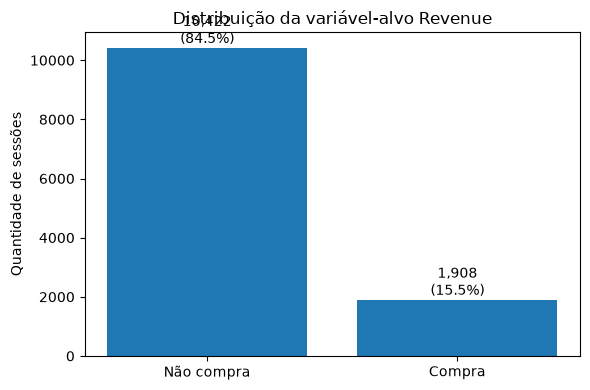

In [7]:
def analisar_distribuicao_alvo(y: pd.Series) -> pd.DataFrame:
    """Retorna contagens e percentuais das duas classes de Revenue."""
    contagens = y.value_counts().reindex([0, 1], fill_value=0)
    tabela = pd.DataFrame({
        "Revenue": [0, 1],
        "interpretacao": ["Não compra", "Compra"],
        "quantidade": [int(contagens.loc[0]), int(contagens.loc[1])],
    })
    tabela["percentual"] = tabela["quantidade"] / len(y) * 100
    return tabela


distribuicao_revenue = analisar_distribuicao_alvo(df[COLUNA_ALVO])
salvar_tabela(distribuicao_revenue, "distribuicao_revenue.csv")
display(distribuicao_revenue)

contagens_reais = distribuicao_revenue.set_index("Revenue")["quantidade"].to_dict()
if (contagens_reais[0], contagens_reais[1]) != (REFERENCIA_UCI["sem_compra"], REFERENCIA_UCI["com_compra"]):
    print(
        "A distribuição de Revenue difere da referência UCI "
        f"(não compra={REFERENCIA_UCI['sem_compra']:,}; compra={REFERENCIA_UCI['com_compra']:,}). "
        "Serão usados os valores realmente carregados."
    )

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(distribuicao_revenue["interpretacao"], distribuicao_revenue["quantidade"])
ax.set_title("Distribuição da variável-alvo Revenue")
ax.set_ylabel("Quantidade de sessões")
for barra, percentual in zip(barras, distribuicao_revenue["percentual"]):
    ax.annotate(f"{int(barra.get_height()):,}\n({percentual:.1f}%)",
                (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha="center", va="bottom")
fig.tight_layout()
salvar_grafico(fig, "distribuicao_revenue.png")
plt.show()

Gráfico salvo: output\distribuicoes_variaveis_numericas.png


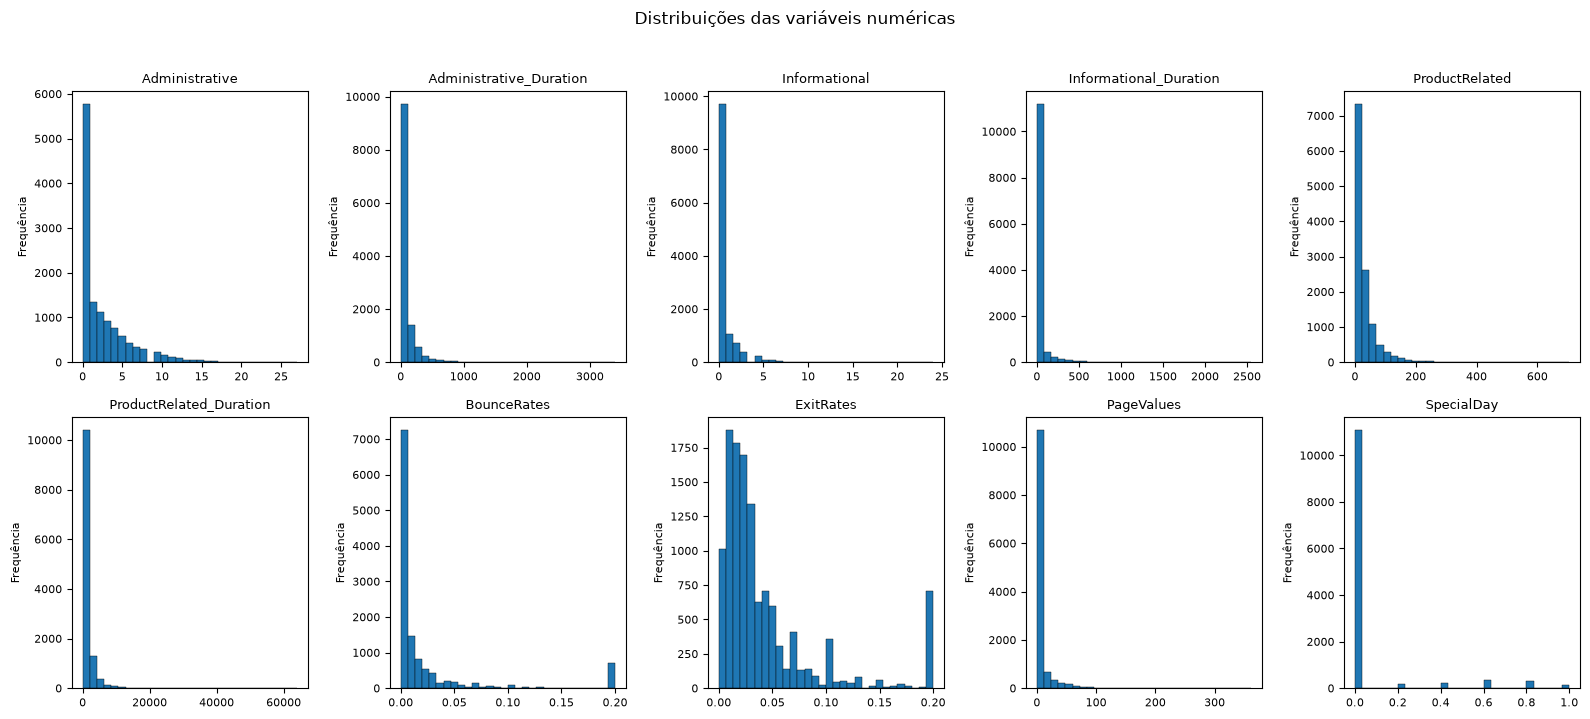

In [8]:
# Para estatísticas e gráficos, infinitos são tratados como ausentes nesta cópia de análise.
df_analise = df.copy()
for coluna in COLUNAS_NUMERICAS:
    df_analise[coluna] = pd.to_numeric(df_analise[coluna], errors="coerce").replace([np.inf, -np.inf], np.nan)

fig, eixos = plt.subplots(2, 5, figsize=(16, 7))
for coluna, ax in zip(COLUNAS_NUMERICAS, eixos.flat):
    valores = df_analise[coluna].dropna()
    if len(valores):
        ax.hist(valores, bins=30, edgecolor="black", linewidth=0.3)
    ax.set_title(coluna, fontsize=9)
    ax.tick_params(axis="both", labelsize=8)
    ax.set_ylabel("Frequência", fontsize=8)
fig.suptitle("Distribuições das variáveis numéricas", y=1.02)
fig.tight_layout()
salvar_grafico(fig, "distribuicoes_variaveis_numericas.png")
plt.show()

Tabela salva: output\outliers_iqr.csv


,variavel,observacoes_validas,quantidade_outliers,percentual_outliers
0,Administrative,12330,404,3.276561
1,Administrative_Duration,12330,1172,9.505272
2,Informational,12330,2631,21.338200
3,Informational_Duration,12330,2405,19.505272
4,ProductRelated,12330,987,8.004866
5,ProductRelated_Duration,12330,961,7.793998
6,BounceRates,12330,1551,12.579075
7,ExitRates,12330,1099,8.913220
8,PageValues,12330,2730,22.141119
9,SpecialDay,12330,1251,10.145985


Gráfico salvo: output\outliers_iqr.png


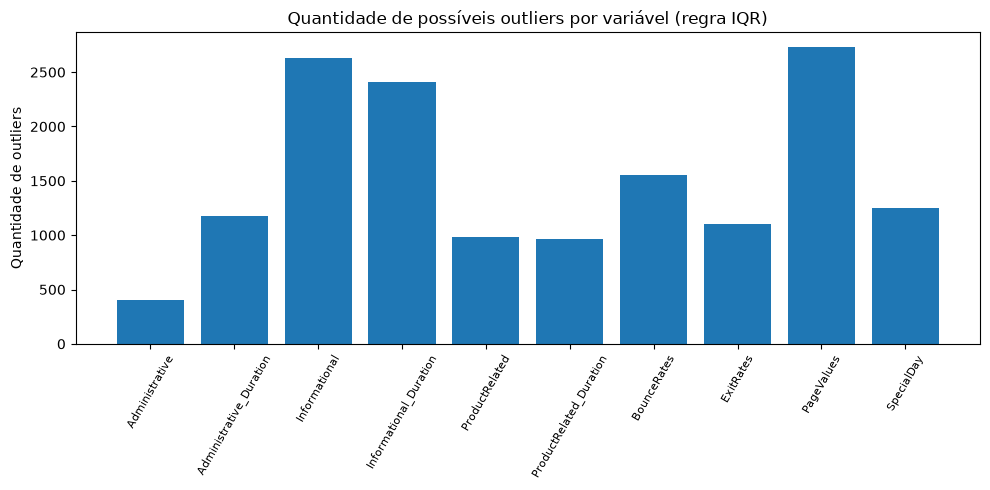

A regra IQR identifica observações extremas em relação à distribuição de cada variável; isso, isoladamente, não significa que sejam erros. Nenhum registro foi removido ou limitado.


In [9]:
def identificar_outliers_iqr(df_numerico: pd.DataFrame, colunas_numericas: list[str]) -> pd.DataFrame:
    """Quantifica valores fora de Q1 - 1,5×IQR e Q3 + 1,5×IQR por variável."""
    resultados = []
    for coluna in colunas_numericas:
        serie = pd.to_numeric(df_numerico[coluna], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
        if serie.empty:
            resultados.append({"variavel": coluna, "observacoes_validas": 0, "limite_inferior": np.nan,
                               "limite_superior": np.nan, "quantidade_outliers": 0, "percentual_outliers": 0.0})
            continue
        q1 = serie.quantile(0.25)
        q3 = serie.quantile(0.75)
        iqr = q3 - q1
        limite_inferior = q1 - 1.5 * iqr
        limite_superior = q3 + 1.5 * iqr
        quantidade = int(((serie < limite_inferior) | (serie > limite_superior)).sum())
        resultados.append({
            "variavel": coluna,
            "observacoes_validas": int(len(serie)),
            "q1": q1,
            "q3": q3,
            "iqr": iqr,
            "limite_inferior": limite_inferior,
            "limite_superior": limite_superior,
            "quantidade_outliers": quantidade,
            "percentual_outliers": 100 * quantidade / len(serie),
        })
    return pd.DataFrame(resultados)


outliers_iqr = identificar_outliers_iqr(df_analise, COLUNAS_NUMERICAS)
salvar_tabela(outliers_iqr, "outliers_iqr.csv")
display(outliers_iqr[["variavel", "observacoes_validas", "quantidade_outliers", "percentual_outliers"]])

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(outliers_iqr["variavel"], outliers_iqr["quantidade_outliers"])
ax.set_title("Quantidade de possíveis outliers por variável (regra IQR)")
ax.set_ylabel("Quantidade de outliers")
ax.tick_params(axis="x", rotation=60, labelsize=8)
fig.tight_layout()
salvar_grafico(fig, "outliers_iqr.png")
plt.show()

print(
    "A regra IQR identifica observações extremas em relação à distribuição de cada variável; "
    "isso, isoladamente, não significa que sejam erros. Nenhum registro foi removido ou limitado."
)

## 5. Tratamento de dados e definição dos atributos

As colunas categóricas incluem `Month`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`, `VisitorType` e `Weekend`. Mesmo quando representadas por números, `OperatingSystems`, `Browser`, `Region` e `TrafficType` são códigos categóricos, não quantidades. Valores infinitos são convertidos em ausentes apenas na cópia usada para modelagem; a imputação será ajustada dentro dos pipelines, durante a validação.

In [10]:
df_modelagem = df.copy()
for coluna in COLUNAS_NUMERICAS:
    df_modelagem[coluna] = pd.to_numeric(df_modelagem[coluna], errors="coerce").replace([np.inf, -np.inf], np.nan)

X = df_modelagem[COLUNAS_PREDITORAS].copy()
y = df_modelagem[COLUNA_ALVO].copy().astype(int)

print(f"Atributos preditores: {X.shape[1]}")
print(f"Registros para modelagem: {len(X):,}")
print(f"Valores ausentes na cópia de modelagem: {int(X.isna().sum().sum()):,}")
print("A distribuição da variável-alvo permanece original; não será aplicado reamostramento.")

Atributos preditores: 17
Registros para modelagem: 12,330
Valores ausentes na cópia de modelagem: 0
A distribuição da variável-alvo permanece original; não será aplicado reamostramento.


## 6. Separação holdout estratificada (80% treino / 20% teste)

O teste fica isolado até a avaliação final. A validação cruzada será realizada exclusivamente sobre o conjunto de treino, utilizando cinco folds estratificados e semente fixa.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Treino: {X_train.shape[0]:,} registros ({X_train.shape[0] / len(X):.1%})")
print(f"Teste:  {X_test.shape[0]:,} registros ({X_test.shape[0] / len(X):.1%})")
print("Distribuição de Revenue no treino:")
display((y_train.value_counts(normalize=True).sort_index() * 100).rename("percentual").to_frame())
print("Distribuição de Revenue no teste:")
display((y_test.value_counts(normalize=True).sort_index() * 100).rename("percentual").to_frame())

Treino: 9,864 registros (80.0%)
Teste:  2,466 registros (20.0%)
Distribuição de Revenue no treino:


,percentual
Revenue,
0,84.529603
1,15.470397


Distribuição de Revenue no teste:


,percentual
Revenue,
0,84.509327
1,15.490673


## 7. Construção dos pipelines e dos modelos

Os imputadores, a codificação one-hot e a padronização são ajustados dentro do pipeline em cada fold, evitando vazamento de dados. A Regressão Logística recebe padronização numérica e peso balanceado de classes; Random Forest também usa pesos balanceados. XGBoost recebe `scale_pos_weight` calculado pela razão entre negativos e positivos apenas no conjunto de treino.

In [12]:
def criar_preprocessador(
    colunas_numericas: list[str],
    colunas_categoricas: list[str],
    padronizar_numericas: bool,
) -> ColumnTransformer:
    """Cria o pré-processamento com imputação e one-hot dentro do pipeline."""
    etapas_numericas = [("imputador", SimpleImputer(strategy="median", keep_empty_features=True))]
    if padronizar_numericas:
        etapas_numericas.append(("escalador", StandardScaler()))
    pipeline_numerico = Pipeline(steps=etapas_numericas)

    pipeline_categorico = Pipeline(steps=[
        ("imputador", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
        ("codificador", OneHotEncoder(handle_unknown="ignore")),
    ])

    return ColumnTransformer(
        transformers=[
            ("num", pipeline_numerico, colunas_numericas),
            ("cat", pipeline_categorico, colunas_categoricas),
        ],
        remainder="drop",
    )


def criar_modelos_e_parametros(y_treino: pd.Series) -> dict:
    """Define pipelines e grids compactos para os três classificadores."""
    positivos = int((y_treino == 1).sum())
    negativos = int((y_treino == 0).sum())
    if positivos == 0:
        raise ValueError("Não há exemplos positivos em y_train para calcular scale_pos_weight.")
    peso_positivo = negativos / positivos

    preprocessador_lr = criar_preprocessador(COLUNAS_NUMERICAS, COLUNAS_CATEGORICAS, True)
    preprocessador_arvores = criar_preprocessador(COLUNAS_NUMERICAS, COLUNAS_CATEGORICAS, False)

    modelos = {
        "Regressão Logística": {
            "pipeline": Pipeline(steps=[
                ("preprocessador", preprocessador_lr),
                ("modelo", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
            ]),
            "parametros": {"modelo__C": [0.1, 1.0, 10.0]},
        },
        "Random Forest": {
            "pipeline": Pipeline(steps=[
                ("preprocessador", preprocessador_arvores),
                ("modelo", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1)),
            ]),
            "parametros": {
                "modelo__n_estimators": [100, 200],
                "modelo__max_depth": [None, 12],
                "modelo__min_samples_leaf": [1, 3],
            },
        },
        "XGBoost": {
            "pipeline": Pipeline(steps=[
                ("preprocessador", preprocessador_arvores),
                ("modelo", XGBClassifier(
                    objective="binary:logistic",
                    eval_metric="logloss",
                    random_state=RANDOM_STATE,
                    tree_method="hist",
                    n_jobs=1,
                    scale_pos_weight=peso_positivo,
                )),
            ]),
            "parametros": {
                "modelo__n_estimators": [100, 200],
                "modelo__max_depth": [3, 5],
                "modelo__learning_rate": [0.05, 0.1],
            },
        },
    }
    print(f"scale_pos_weight do XGBoost (calculado apenas com y_train): {peso_positivo:.4f}")
    return modelos


modelos_configurados = criar_modelos_e_parametros(y_train)
for nome, configuracao in modelos_configurados.items():
    quantidade = int(np.prod([len(v) for v in configuracao["parametros"].values()]))
    print(f"{nome}: {quantidade} combinações de hiperparâmetros")
print("Total configurado: 19 combinações × 5 folds = 95 ajustes de validação cruzada, antes dos refits finais.")

scale_pos_weight do XGBoost (calculado apenas com y_train): 5.4640
Regressão Logística: 3 combinações de hiperparâmetros
Random Forest: 8 combinações de hiperparâmetros
XGBoost: 8 combinações de hiperparâmetros
Total configurado: 19 combinações × 5 folds = 95 ajustes de validação cruzada, antes dos refits finais.


## 8. Grid Search e validação cruzada

A busca seleciona a configuração com maior AUC-ROC média (`refit="roc_auc"`) e também registra F1, precisão, recall e acurácia. `n_jobs=-1` é utilizado no `GridSearchCV`; os estimadores internos permanecem com paralelismo configurado em um processo para evitar paralelismo aninhado. A execução completa pode levar algum tempo, dependendo do equipamento.

In [13]:
SCORING = {
    "roc_auc": "roc_auc",
    "f1": "f1",
    "precision": "precision",
    "recall": "recall",
    "accuracy": "accuracy",
}
CV = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)


def executar_busca(nome_modelo: str, pipeline: Pipeline, parametros: dict):
    """Executa o Grid Search e retorna o objeto treinado, tempo e resultados."""
    busca = GridSearchCV(
        estimator=pipeline,
        param_grid=parametros,
        scoring=SCORING,
        refit="roc_auc",
        cv=CV,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise",
        verbose=1,
    )
    inicio = time.perf_counter()
    busca.fit(X_train, y_train)
    duracao = time.perf_counter() - inicio

    resultados = pd.DataFrame(busca.cv_results_)
    resultados.insert(0, "modelo", nome_modelo)
    resultados["parametros"] = resultados["params"].map(
        lambda valor: json.dumps(valor, ensure_ascii=False, default=str)
    )
    colunas_metricas = [
        coluna for coluna in resultados.columns
        if coluna.startswith(("mean_test_", "std_test_", "rank_test_"))
    ]
    colunas_tempo = [coluna for coluna in ["mean_fit_time", "std_fit_time", "mean_score_time", "std_score_time"] if coluna in resultados]
    resultados = resultados[["modelo", "parametros"] + colunas_metricas + colunas_tempo]
    return busca, duracao, resultados


buscas = {}
tempos_busca = {}
resultados_grids = []

for nome, configuracao in modelos_configurados.items():
    print(f"\n{'=' * 70}\nBusca: {nome}\n{'=' * 70}")
    busca, duracao, tabela_grid = executar_busca(
        nome,
        configuracao["pipeline"],
        configuracao["parametros"],
    )
    buscas[nome] = busca
    tempos_busca[nome] = duracao
    resultados_grids.append(tabela_grid)
    print(f"Melhor AUC-ROC média na validação cruzada: {busca.best_score_:.4f}")
    print(f"Melhores parâmetros: {busca.best_params_}")
    print(f"Tempo da busca (inclui refit): {duracao:.1f} s")

resultados_grid_search = pd.concat(resultados_grids, ignore_index=True)
salvar_tabela(resultados_grid_search, "resultados_grid_search.csv")
display(resultados_grid_search.sort_values(["modelo", "rank_test_roc_auc"]).reset_index(drop=True))


Busca: Regressão Logística
Fitting 5 folds for each of 3 candidates, totalling 15 fits


Melhor AUC-ROC média na validação cruzada: 0.9056
Melhores parâmetros: {'modelo__C': 0.1}
Tempo da busca (inclui refit): 5.1 s

Busca: Random Forest
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Melhor AUC-ROC média na validação cruzada: 0.9285
Melhores parâmetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 200}
Tempo da busca (inclui refit): 16.4 s

Busca: XGBoost
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Melhor AUC-ROC média na validação cruzada: 0.9338
Melhores parâmetros: {'modelo__learning_rate': 0.05, 'modelo__max_depth': 3, 'modelo__n_estimators': 200}
Tempo da busca (inclui refit): 2.1 s
Tabela salva: output\resultados_grid_search.csv


,modelo,parametros,mean_test_roc_auc,std_test_roc_auc,rank_test_roc_auc,mean_test_f1,std_test_f1,rank_test_f1,mean_test_precision,std_test_precision,...,mean_test_recall,std_test_recall,rank_test_recall,mean_test_accuracy,std_test_accuracy,rank_test_accuracy,mean_fit_time,std_fit_time,mean_score_time,std_score_time
0,Random Forest,"{""modelo__max_depth"": null, ""modelo__min_sampl...",0.928451,0.003694,1,0.674436,0.014859,3,0.579632,0.026129,...,0.807993,0.014175,6,0.879056,0.009761,3,5.445411,0.085489,0.203303,0.006270
1,Random Forest,"{""modelo__max_depth"": null, ""modelo__min_sampl...",0.928420,0.003472,2,0.673902,0.011213,4,0.577729,0.022105,...,0.809962,0.015768,5,0.878549,0.008083,4,2.817408,0.020970,0.137488,0.007733
2,Random Forest,"{""modelo__max_depth"": null, ""modelo__min_sampl...",0.927257,0.003221,3,0.681446,0.016765,1,0.646409,0.029327,...,0.721496,0.013074,7,0.895479,0.007897,1,7.356366,0.059962,0.239779,0.005962
3,Random Forest,"{""modelo__max_depth"": 12, ""modelo__min_samples...",0.926736,0.004511,4,0.667860,0.016845,6,0.558426,0.021943,...,0.831570,0.015333,1,0.871858,0.009336,7,3.091304,0.139670,0.116133,0.006254
4,Random Forest,"{""modelo__max_depth"": null, ""modelo__min_sampl...",0.926600,0.002973,5,0.678007,0.014697,2,0.644649,0.026086,...,0.716258,0.021712,8,0.894668,0.006765,2,3.763359,0.234881,0.143861,0.022415
5,Random Forest,"{""modelo__max_depth"": 12, ""modelo__min_samples...",0.926098,0.004300,6,0.665952,0.014636,8,0.557621,0.021556,...,0.827644,0.013807,2,0.871351,0.009017,8,1.944498,0.023895,0.128145,0.013047
6,Random Forest,"{""modelo__max_depth"": 12, ""modelo__min_samples...",0.923783,0.004647,7,0.670205,0.016051,5,0.569096,0.025925,...,0.816511,0.011581,3,0.875406,0.010118,5,4.057673,0.050257,0.162500,0.008519
7,Random Forest,"{""modelo__max_depth"": 12, ""modelo__min_samples...",0.923460,0.004657,8,0.666996,0.016666,7,0.565684,0.025917,...,0.813890,0.008689,4,0.873987,0.010354,6,2.115491,0.019941,0.129165,0.005680
8,Regressão Logística,"{""modelo__C"": 0.1}",0.905550,0.006497,1,0.621169,0.020215,1,0.524510,0.024760,...,0.762119,0.010157,3,0.855941,0.010592,1,0.181712,0.024340,0.049269,0.003352
9,Regressão Logística,"{""modelo__C"": 1.0}",0.904412,0.006496,2,0.616914,0.021868,2,0.517280,0.025854,...,0.764742,0.013376,1,0.852798,0.011333,2,0.202445,0.007449,0.051182,0.002864


## 9. Avaliação no conjunto de teste

Somente após a busca, cada melhor pipeline é avaliado no holdout de teste. As probabilidades são usadas para calcular AUC-ROC; a classe prevista é definida pelo limiar fixo de 0,5, que não é otimizado com o teste. Um falso positivo representa uma compra prevista que não ocorreu; um falso negativo representa uma compra real não identificada.

Tabela salva: output\matriz_confusao_regressao_logistica.csv
Gráfico salvo: output\matriz_confusao_regressao_logistica.png


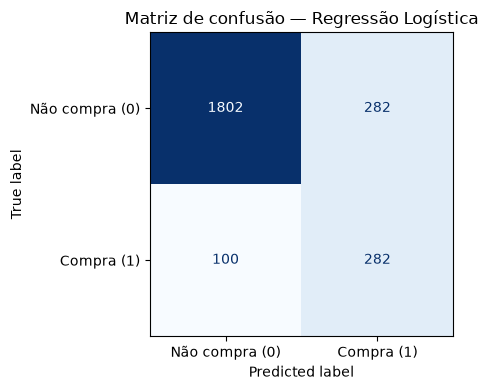

Tabela salva: output\matriz_confusao_random_forest.csv
Gráfico salvo: output\matriz_confusao_random_forest.png


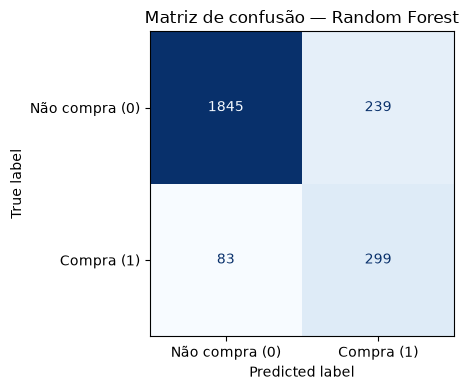

Tabela salva: output\matriz_confusao_xgboost.csv
Gráfico salvo: output\matriz_confusao_xgboost.png


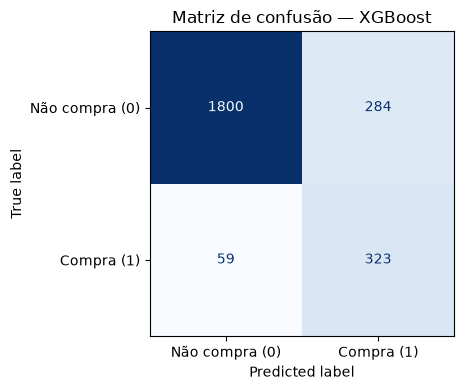

Tabela salva: output\metricas_teste.csv


,modelo,roc_auc,f1,precision,recall,accuracy
0,XGBoost,0.932530,0.653185,0.532125,0.845550,0.860908
1,Random Forest,0.921276,0.650000,0.555762,0.782723,0.869424
2,Regressão Logística,0.894907,0.596195,0.500000,0.738220,0.845093


In [14]:
def avaliar_modelo(modelo_treinado, X_avaliacao: pd.DataFrame, y_real: pd.Series) -> dict:
    """Calcula métricas, probabilidades, classes previstas e matriz de confusão."""
    probabilidades = modelo_treinado.predict_proba(X_avaliacao)[:, 1]
    previsoes = (probabilidades >= LIMIAR_CLASSIFICACAO).astype(int)
    metricas = {
        "roc_auc": roc_auc_score(y_real, probabilidades),
        "f1": f1_score(y_real, previsoes, zero_division=0),
        "precision": precision_score(y_real, previsoes, zero_division=0),
        "recall": recall_score(y_real, previsoes, zero_division=0),
        "accuracy": accuracy_score(y_real, previsoes),
    }
    matriz = confusion_matrix(y_real, previsoes, labels=[0, 1])
    return {
        "metricas": metricas,
        "probabilidades": probabilidades,
        "previsoes": previsoes,
        "matriz_confusao": matriz,
    }



def plotar_matriz_confusao(
    matriz: np.ndarray,
    nome_modelo: str,
    nome_arquivo: str
) -> None:
    """Exibe e exporta uma matriz de confusão em tons de azul."""
    figura, ax = plt.subplots(figsize=(5, 4))

    exibicao = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["Não compra (0)", "Compra (1)"],
    )

    exibicao.plot(
        ax=ax,
        values_format="d",
        colorbar=False,
        cmap="Blues",
    )

    ax.set_title(f"Matriz de confusão — {nome_modelo}")
    figura.tight_layout()

    salvar_grafico(figura, nome_arquivo)
    plt.show()


resultados_teste = {}
linhas_metricas_teste = []

nomes_arquivo = {
    "Regressão Logística": "regressao_logistica",
    "Random Forest": "random_forest",
    "XGBoost": "xgboost",
}

for nome, busca in buscas.items():
    resultado = avaliar_modelo(busca.best_estimator_, X_test, y_test)
    resultados_teste[nome] = resultado
    linhas_metricas_teste.append({"modelo": nome, **resultado["metricas"]})

    nome_base = nomes_arquivo[nome]
    matriz = resultado["matriz_confusao"]
    matriz_df = pd.DataFrame(
        matriz,
        columns=["previsto_nao_compra", "previsto_compra"],
    )
    matriz_df.insert(0, "classe_real", ["nao_compra", "compra"])
    salvar_tabela(matriz_df, f"matriz_confusao_{nome_base}.csv")
    plotar_matriz_confusao(matriz, nome, f"matriz_confusao_{nome_base}.png")

metricas_teste = pd.DataFrame(linhas_metricas_teste).sort_values("roc_auc", ascending=False).reset_index(drop=True)
salvar_tabela(metricas_teste, "metricas_teste.csv")
display(metricas_teste)

## 10. Comparação de desempenho e análise de variáveis importantes

A comparação combina as médias e desvios-padrão da validação cruzada para a melhor configuração de cada modelo com as métricas do teste. Os coeficientes da Regressão Logística preservam o sinal; para Random Forest e XGBoost, são apresentadas importâncias de atributos. Essas medidas têm significados e escalas diferentes e não devem ser comparadas diretamente entre algoritmos.

Tabela salva: output\metricas_validacao_cruzada.csv


,modelo,auc_roc_cv,f1_cv,precision_cv,recall_cv,accuracy_cv,desvio_auc_roc_cv,desvio_f1_cv,desvio_precision_cv,desvio_recall_cv,desvio_accuracy_cv
0,Regressão Logística,0.905550,0.621169,0.524510,0.762119,0.855941,0.006497,0.020215,0.024760,0.010157,0.010592
1,Random Forest,0.928451,0.674436,0.579632,0.807993,0.879056,0.003694,0.014859,0.026129,0.014175,0.009761
2,XGBoost,0.933786,0.661157,0.540301,0.852538,0.864660,0.004108,0.014683,0.018897,0.016059,0.008601


Gráfico salvo: output\curva_roc_comparativa.png


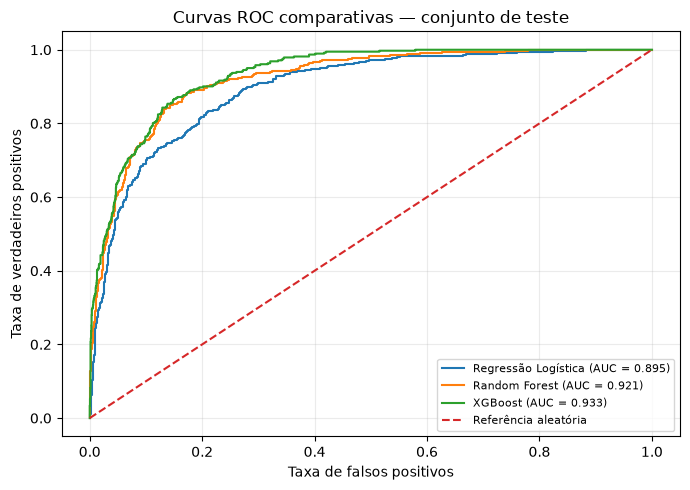

In [15]:
linhas_cv = []
for nome, busca in buscas.items():
    indice = busca.best_index_
    linha = {"modelo": nome, "auc_roc_cv": float(busca.cv_results_["mean_test_roc_auc"][indice]),
             "f1_cv": float(busca.cv_results_["mean_test_f1"][indice]),
             "precision_cv": float(busca.cv_results_["mean_test_precision"][indice]),
             "recall_cv": float(busca.cv_results_["mean_test_recall"][indice]),
             "accuracy_cv": float(busca.cv_results_["mean_test_accuracy"][indice]),
             "desvio_auc_roc_cv": float(busca.cv_results_["std_test_roc_auc"][indice]),
             "desvio_f1_cv": float(busca.cv_results_["std_test_f1"][indice]),
             "desvio_precision_cv": float(busca.cv_results_["std_test_precision"][indice]),
             "desvio_recall_cv": float(busca.cv_results_["std_test_recall"][indice]),
             "desvio_accuracy_cv": float(busca.cv_results_["std_test_accuracy"][indice])}
    linhas_cv.append(linha)

metricas_validacao_cruzada = pd.DataFrame(linhas_cv)
salvar_tabela(metricas_validacao_cruzada, "metricas_validacao_cruzada.csv")
display(metricas_validacao_cruzada)

fig, ax = plt.subplots(figsize=(7, 5))
for nome, resultado in resultados_teste.items():
    fpr, tpr, _ = roc_curve(y_test, resultado["probabilidades"])
    auc_teste = resultado["metricas"]["roc_auc"]
    ax.plot(fpr, tpr, label=f"{nome} (AUC = {auc_teste:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", label="Referência aleatória")
ax.set_xlabel("Taxa de falsos positivos")
ax.set_ylabel("Taxa de verdadeiros positivos")
ax.set_title("Curvas ROC comparativas — conjunto de teste")
ax.legend(loc="lower right", fontsize=8)
ax.grid(alpha=0.25)
fig.tight_layout()
salvar_grafico(fig, "curva_roc_comparativa.png")
plt.show()

Tabela salva: output\importancia_variaveis_regressao_logistica.csv


### Variáveis mais relevantes — Regressão Logística

,variavel,coeficiente,coeficiente_absoluto,direcao
0,PageValues,2.210400,2.210400,positivo
1,Month_Nov,0.702514,0.702514,positivo
2,ExitRates,-0.605588,0.605588,negativo
3,Month_Feb,-0.595730,0.595730,negativo
4,Month_May,-0.557731,0.557731,negativo
5,TrafficType_13,-0.516574,0.516574,negativo
6,Month_Sep,0.473683,0.473683,positivo
7,Month_Mar,-0.471184,0.471184,negativo
8,TrafficType_8,0.461907,0.461907,positivo
9,Browser_12,0.436987,0.436987,positivo


Gráfico salvo: output\importancia_variaveis_regressao_logistica.png


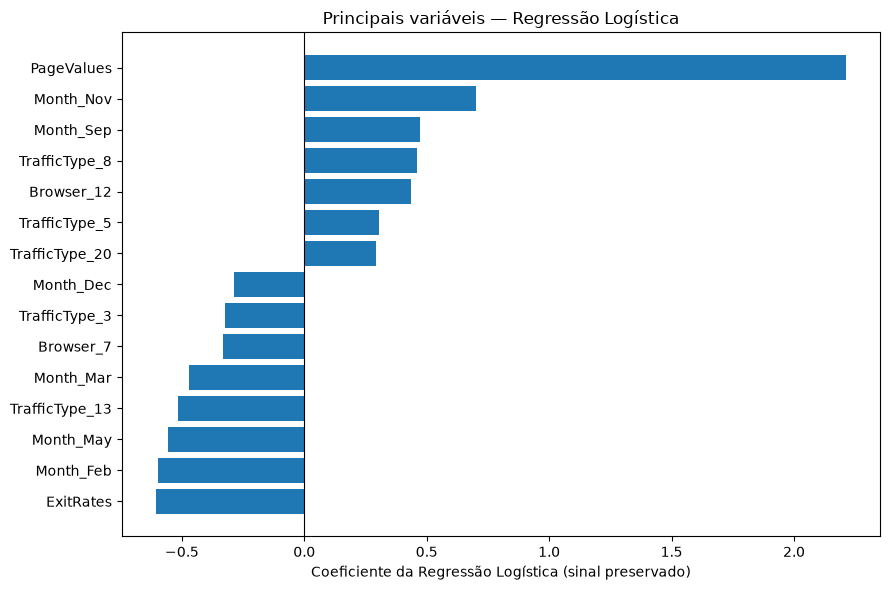

Tabela salva: output\importancia_variaveis_random_forest.csv


### Variáveis mais relevantes — Random Forest

,variavel,importancia
0,PageValues,0.423296
1,ExitRates,0.088636
2,ProductRelated_Duration,0.075385
3,ProductRelated,0.066248
4,BounceRates,0.056143
5,Administrative_Duration,0.039435
6,Administrative,0.035937
7,Month_Nov,0.026933
8,Informational_Duration,0.015896
9,Informational,0.012772


Gráfico salvo: output\importancia_variaveis_random_forest.png


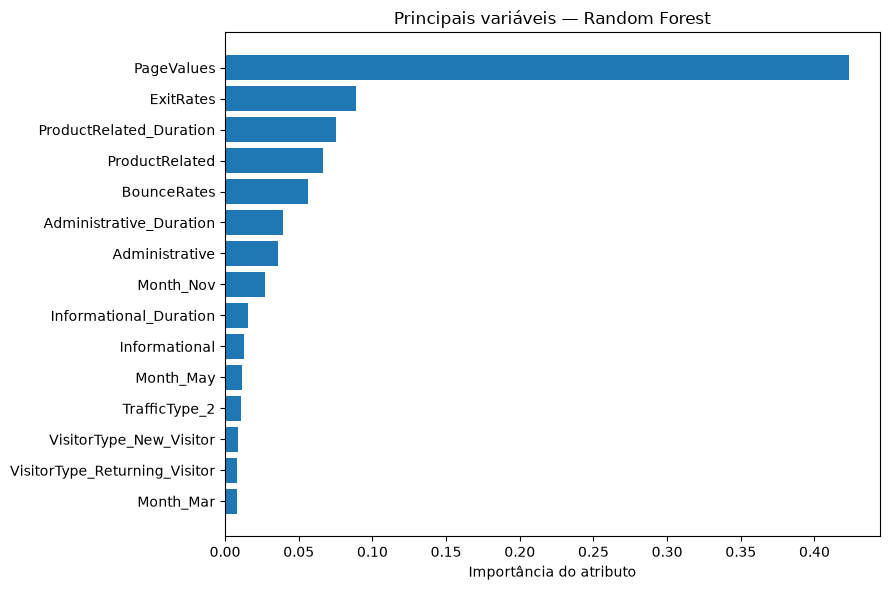

Tabela salva: output\importancia_variaveis_xgboost.csv


### Variáveis mais relevantes — XGBoost

,variavel,importancia
0,PageValues,0.297890
1,Month_Nov,0.080635
2,Month_Mar,0.072156
3,Month_May,0.059720
4,Month_Sep,0.056954
5,ProductRelated,0.022380
6,Administrative_Duration,0.021318
7,VisitorType_Returning_Visitor,0.020933
8,ExitRates,0.020009
9,BounceRates,0.019539


Gráfico salvo: output\importancia_variaveis_xgboost.png


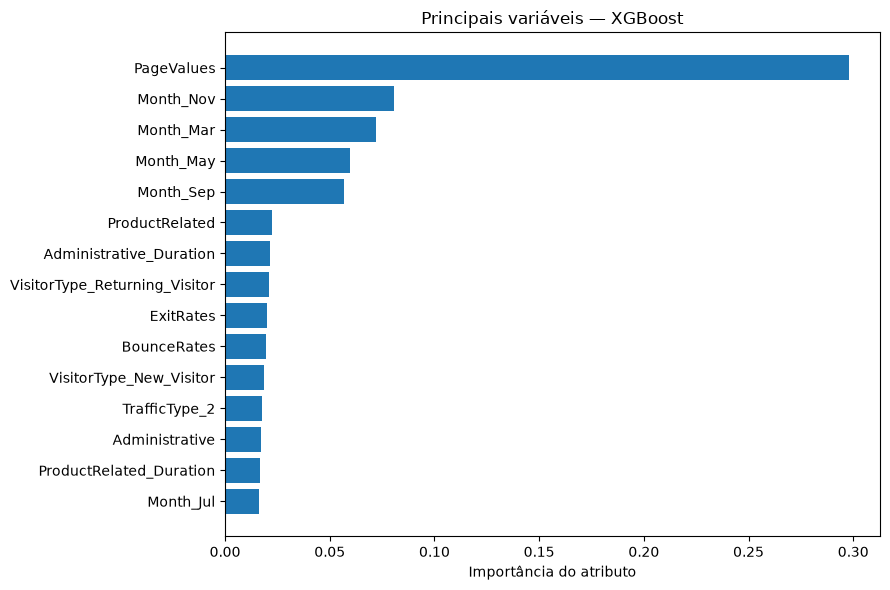

In [16]:
def extrair_importancia_variaveis(nome_modelo: str, pipeline_treinado: Pipeline) -> pd.DataFrame:
    """Extrai coeficientes ou importâncias usando os nomes pós-OneHotEncoder."""
    preprocessador = pipeline_treinado.named_steps["preprocessador"]
    modelo = pipeline_treinado.named_steps["modelo"]
    nomes_atributos = preprocessador.get_feature_names_out()
    # Remove somente os prefixos internos do ColumnTransformer; preserva o nome codificado.
    nomes_atributos = [nome.replace("num__", "", 1).replace("cat__", "", 1) for nome in nomes_atributos]

    if nome_modelo == "Regressão Logística":
        coeficientes = modelo.coef_.ravel()
        tabela = pd.DataFrame({"variavel": nomes_atributos, "coeficiente": coeficientes})
        tabela["coeficiente_absoluto"] = tabela["coeficiente"].abs()
        tabela["direcao"] = np.where(tabela["coeficiente"] >= 0, "positivo", "negativo")
        return tabela.sort_values("coeficiente_absoluto", ascending=False).reset_index(drop=True)

    importancias = modelo.feature_importances_
    return pd.DataFrame({"variavel": nomes_atributos, "importancia": importancias}).sort_values(
        "importancia", ascending=False
    ).reset_index(drop=True)


def plotar_importancias(tabela: pd.DataFrame, nome_modelo: str, nome_base: str, top_n: int = 15) -> None:
    """Exibe e exporta as principais variáveis do modelo, respeitando o tipo da medida."""
    top = tabela.head(top_n).copy()
    figura, ax = plt.subplots(figsize=(9, 6))
    if "coeficiente" in top.columns:
        top = top.sort_values("coeficiente", ascending=True)
        ax.barh(top["variavel"], top["coeficiente"])
        ax.axvline(0, color="black", linewidth=0.8)
        ax.set_xlabel("Coeficiente da Regressão Logística (sinal preservado)")
    else:
        top = top.sort_values("importancia", ascending=True)
        ax.barh(top["variavel"], top["importancia"])
        ax.set_xlabel("Importância do atributo")
    ax.set_title(f"Principais variáveis — {nome_modelo}")
    figura.tight_layout()
    salvar_grafico(figura, f"importancia_variaveis_{nome_base}.png")
    plt.show()


tabelas_importancia = {}
for nome, busca in buscas.items():
    tabela = extrair_importancia_variaveis(nome, busca.best_estimator_)
    tabelas_importancia[nome] = tabela
    nome_base = nomes_arquivo[nome]
    salvar_tabela(tabela, f"importancia_variaveis_{nome_base}.csv")
    display(Markdown(f"### Variáveis mais relevantes — {nome}"))
    display(tabela.head(15))
    plotar_importancias(tabela, nome, nome_base, top_n=15)

In [17]:
def montar_comparativo(
    metricas_cv: pd.DataFrame,
    metricas_holdout: pd.DataFrame,
    buscas_por_modelo: dict,
    tempos: dict,
) -> pd.DataFrame:
    """Consolida métricas de CV e teste, parâmetros, tempo e interpretabilidade."""
    interpretabilidade = {
        "Regressão Logística": "Maior interpretabilidade relativa; coeficientes lineares com sinal.",
        "Random Forest": "Relações não lineares; importâncias globais, interpretação menos direta.",
        "XGBoost": "Boosting não linear; importâncias globais, interpretação menos direta.",
    }
    comparativo = metricas_cv.merge(metricas_holdout, on="modelo", suffixes=("", "_teste"))
    comparativo = comparativo.rename(columns={
        "roc_auc": "auc_roc_teste",
        "f1": "f1_teste",
        "precision": "precision_teste",
        "recall": "recall_teste",
        "accuracy": "accuracy_teste",
    })
    comparativo["melhores_parametros"] = comparativo["modelo"].map(
        lambda nome: json.dumps(buscas_por_modelo[nome].best_params_, ensure_ascii=False, default=str)
    )
    comparativo["tempo_busca_segundos"] = comparativo["modelo"].map(tempos)
    comparativo["interpretabilidade"] = comparativo["modelo"].map(interpretabilidade)
    comparativo["diferenca_absoluta_auc_cv_teste"] = (comparativo["auc_roc_cv"] - comparativo["auc_roc_teste"]).abs()
    return comparativo.sort_values("auc_roc_cv", ascending=False).reset_index(drop=True)


comparativo_modelos = montar_comparativo(metricas_validacao_cruzada, metricas_teste, buscas, tempos_busca)
salvar_tabela(comparativo_modelos, "comparativo_modelos.csv")
display(comparativo_modelos)

Tabela salva: output\comparativo_modelos.csv


,modelo,auc_roc_cv,f1_cv,precision_cv,recall_cv,accuracy_cv,desvio_auc_roc_cv,desvio_f1_cv,desvio_precision_cv,desvio_recall_cv,desvio_accuracy_cv,auc_roc_teste,f1_teste,precision_teste,recall_teste,accuracy_teste,melhores_parametros,tempo_busca_segundos,interpretabilidade,diferenca_absoluta_auc_cv_teste
0,XGBoost,0.933786,0.661157,0.540301,0.852538,0.864660,0.004108,0.014683,0.018897,0.016059,0.008601,0.932530,0.653185,0.532125,0.845550,0.860908,"{""modelo__learning_rate"": 0.05, ""modelo__max_d...",2.074934,"Boosting não linear; importâncias globais, int...",0.001256
1,Random Forest,0.928451,0.674436,0.579632,0.807993,0.879056,0.003694,0.014859,0.026129,0.014175,0.009761,0.921276,0.650000,0.555762,0.782723,0.869424,"{""modelo__max_depth"": null, ""modelo__min_sampl...",16.375178,"Relações não lineares; importâncias globais, i...",0.007174
2,Regressão Logística,0.905550,0.621169,0.524510,0.762119,0.855941,0.006497,0.020215,0.024760,0.010157,0.010592,0.894907,0.596195,0.500000,0.738220,0.845093,"{""modelo__C"": 0.1}",5.102480,Maior interpretabilidade relativa; coeficiente...,0.010643


## 11. Conclusão baseada nos resultados calculados

A conclusão abaixo é preenchida com as métricas geradas pela execução. A AUC-ROC média na validação cruzada é o critério principal e o F1-Score é secundário; diferenças no conjunto de teste, consistência, interpretabilidade e complexidade também precisam ser avaliadas. A base não contém custos ou margens de negócio que permitam estimar benefícios financeiros.

In [18]:
ordenado_auc = comparativo_modelos.sort_values("auc_roc_cv", ascending=False).reset_index(drop=True)
principal = ordenado_auc.iloc[0]
segundo = ordenado_auc.iloc[1]
melhor_f1 = comparativo_modelos.sort_values("f1_cv", ascending=False).iloc[0]

texto_conclusao = f"""
### Síntese automática dos resultados

- **Maior AUC-ROC média na validação cruzada:** {principal['modelo']} (AUC-ROC CV = {principal['auc_roc_cv']:.4f}; F1 CV = {principal['f1_cv']:.4f}; AUC-ROC teste = {principal['auc_roc_teste']:.4f}; F1 teste = {principal['f1_teste']:.4f}).
- **Segundo maior AUC-ROC médio na validação cruzada:** {segundo['modelo']} (AUC-ROC CV = {segundo['auc_roc_cv']:.4f}). A diferença absoluta entre os dois valores de AUC-ROC CV é {abs(principal['auc_roc_cv'] - segundo['auc_roc_cv']):.4f}; avalie essa diferença no contexto dos desvios da validação e das métricas no teste.
- **Maior F1-Score médio na validação cruzada:** {melhor_f1['modelo']} (F1 CV = {melhor_f1['f1_cv']:.4f}; precisão CV = {melhor_f1['precision_cv']:.4f}; recall CV = {melhor_f1['recall_cv']:.4f}).
- **Consistência entre CV e teste para o modelo com maior AUC-ROC CV:** diferença absoluta de {principal['diferenca_absoluta_auc_cv_teste']:.4f} entre AUC-ROC CV e AUC-ROC teste.

O maior valor de AUC-ROC na validação cruzada identifica o candidato prioritário segundo o critério definido, mas não deve ser interpretado isoladamente como vencedor definitivo. A decisão final deve considerar o F1-Score, precisão e recall, matrizes de confusão, desempenho no holdout, variação entre folds, tempo de busca e interpretabilidade. A Regressão Logística oferece coeficientes mais diretamente interpretáveis; Random Forest e XGBoost conseguem representar relações não lineares, mas são menos transparentes. Os resultados não demonstram causalidade nem permitem inferir benefício financeiro sem dados adicionais de custos, margens e uso operacional.
"""
display(Markdown(texto_conclusao))


### Síntese automática dos resultados

- **Maior AUC-ROC média na validação cruzada:** XGBoost (AUC-ROC CV = 0.9338; F1 CV = 0.6612; AUC-ROC teste = 0.9325; F1 teste = 0.6532).
- **Segundo maior AUC-ROC médio na validação cruzada:** Random Forest (AUC-ROC CV = 0.9285). A diferença absoluta entre os dois valores de AUC-ROC CV é 0.0053; avalie essa diferença no contexto dos desvios da validação e das métricas no teste.
- **Maior F1-Score médio na validação cruzada:** Random Forest (F1 CV = 0.6744; precisão CV = 0.5796; recall CV = 0.8080).
- **Consistência entre CV e teste para o modelo com maior AUC-ROC CV:** diferença absoluta de 0.0013 entre AUC-ROC CV e AUC-ROC teste.

O maior valor de AUC-ROC na validação cruzada identifica o candidato prioritário segundo o critério definido, mas não deve ser interpretado isoladamente como vencedor definitivo. A decisão final deve considerar o F1-Score, precisão e recall, matrizes de confusão, desempenho no holdout, variação entre folds, tempo de busca e interpretabilidade. A Regressão Logística oferece coeficientes mais diretamente interpretáveis; Random Forest e XGBoost conseguem representar relações não lineares, mas são menos transparentes. Os resultados não demonstram causalidade nem permitem inferir benefício financeiro sem dados adicionais de custos, margens e uso operacional.


## 12. Checklist de execução e arquivos gerados

Ao concluir a execução, confirme se as células foram executadas em ordem, se as três buscas foram concluídas e se os arquivos abaixo estão na pasta `output`. Não foram salvos modelos serializados nem dados intermediários desnecessários.

In [ ]:
arquivos_esperados = [
    "resumo_qualidade_dados.csv",
    "distribuicao_revenue.csv",
    "outliers_iqr.csv",
    "resultados_grid_search.csv",
    "metricas_validacao_cruzada.csv",
    "metricas_teste.csv",
    "comparativo_modelos.csv",
    "matriz_confusao_regressao_logistica.csv",
    "matriz_confusao_random_forest.csv",
    "matriz_confusao_xgboost.csv",
    "importancia_variaveis_regressao_logistica.csv",
    "importancia_variaveis_random_forest.csv",
    "importancia_variaveis_xgboost.csv",
    "distribuicao_revenue.png",
    "distribuicoes_variaveis_numericas.png",
    "outliers_iqr.png",
    "curva_roc_comparativa.png",
    "matriz_confusao_regressao_logistica.png",
    "matriz_confusao_random_forest.png",
    "matriz_confusao_xgboost.png",
    "importancia_variaveis_regressao_logistica.png",
    "importancia_variaveis_random_forest.png",
    "importancia_variaveis_xgboost.png",
]

print(f"\nPasta de saída: {PASTA_SAIDA.resolve()}")
print("Arquivos esperados após a execução completa:")
for arquivo in arquivos_esperados:
    print(f" - {PASTA_SAIDA / arquivo}")

Checklist:
[x] Base e variável-alvo validadas
[x] Holdout estratificado 80/20 e CV de 5 folds definidos
[x] Pré-processamento dentro dos pipelines
[x] Duplicidades mantidas e outliers quantificados sem remoção
[x] Grids compactos definidos: 3 + 8 + 8 combinações
[x] Métricas CV e teste separadas e exportações implementadas
[ ] Executar todas as células e conferir os arquivos gerados

Pasta de saída: C:\Users\joaov\OneDrive\Área de Trabalho\TGI_2\projeto_atualizado\output
Arquivos esperados após a execução completa:
 - output\resumo_qualidade_dados.csv
 - output\distribuicao_revenue.csv
 - output\outliers_iqr.csv
 - output\resultados_grid_search.csv
 - output\metricas_validacao_cruzada.csv
 - output\metricas_teste.csv
 - output\comparativo_modelos.csv
 - output\matriz_confusao_regressao_logistica.csv
 - output\matriz_confusao_random_forest.csv
 - output\matriz_confusao_xgboost.csv
 - output\importancia_variaveis_regressao_logistica.csv
 - output\importancia_variaveis_random_forest.csv
 